# Evaluating the calibration of a TSFM on your own data

This notebook walks through the full `tsfm-calibration` workflow:

1. turn a long-format table into rolling evaluation windows,
2. forecast with a time series foundation model,
3. audit calibration with the PCE / QCE hierarchy and its two cancellation gaps,
4. test whether the gaps are real,
5. recalibrate on a chronological split and see what a global map can and cannot fix,
6. plug in your own model.

The example is **Chronos-2 on M_DENSE/H**: 30 hourly series downloaded from the GIFT-Eval Hugging Face repository (about 17 MB; no GIFT-Eval installation needed). Forecasting takes about 25 s on a GPU and a few minutes on a CPU.

```bash
pip install "tsfm-calibration[chronos,notebook]"
```

With the environment variable `TSFM_DEMO_OFFLINE=1`, the notebook instead uses synthetic data and the seasonal-naive baseline (CPU, no downloads; this is what CI runs).

In [1]:
import os
import warnings

import numpy as np
import pandas as pd

import tsfm_calibration as tc
from tsfm_calibration.plotting import plot_diagnostics

OFFLINE = os.environ.get("TSFM_DEMO_OFFLINE") == "1"
warnings.filterwarnings("ignore", message="IProgress not found")  # tqdm without ipywidgets

## 1. Data → rolling windows

Any long-format table with one row per (series, time step) works. Here, each M_DENSE series becomes `item_id`, `timestamp`, `target` rows.

In [2]:
if OFFLINE:  # hourly series with known defects for the seasonal-naive baseline, see examples/quickstart.py
    rng, rows = np.random.default_rng(0), []
    cycle = np.sin(2 * np.pi * (np.arange(24) - 6) / 24)
    vol = np.where(np.arange(60) >= 48, 2.0, 1.0)
    for i in range(100):
        daily = np.zeros(60)
        for d in range(1, 60):
            daily[d] = 0.8 * daily[d - 1] + rng.normal()
        x = (rng.uniform(95, 105) + rng.uniform(5, 15) * (1 + 0.08 * np.arange(60))[:, None] * cycle
             + daily[:, None] + vol[:, None] * (1 + 0.3 * (cycle > 0.5)) * rng.normal(size=(60, 24)))
        rows.append(pd.DataFrame({"item_id": f"s{i}", "timestamp": np.arange(1440), "target": x.ravel()}))
    df = pd.concat(rows)
else:
    import pyarrow as pa
    from huggingface_hub import hf_hub_download

    path = hf_hub_download("Salesforce/GiftEval", "M_DENSE/H/data-00000-of-00001.arrow", repo_type="dataset")
    table = pa.ipc.open_stream(path).read_all().to_pandas()
    df = pd.concat([pd.DataFrame({"item_id": r.item_id, "target": np.asarray(r.target, dtype=float),
                                  "timestamp": pd.date_range(r.start, periods=len(r.target), freq="h")})
                    for r in table.itertuples()])
df.head()

,item_id,target,timestamp
0,0,679.50,2018-01-01 00:00:00
1,0,3291.00,2018-01-01 01:00:00
2,0,3422.25,2018-01-01 02:00:00
3,0,2046.00,2018-01-01 03:00:00
4,0,982.50,2018-01-01 04:00:00


In [3]:
H, W = (24, 10) if OFFLINE else (48, 20)   # GIFT-Eval short term for hourly data: 20 windows of 48 steps
series = tc.from_dataframe(df, id_col="item_id", time_col="timestamp", target_col="target")
windows = tc.rolling_windows(series, prediction_length=H, num_windows=W)
print(f"{len(series)} series -> {len(windows)} windows of horizon {H}")

30 series -> 600 windows of horizon 48


## 2. Forecast

`tc.forecast` accepts a registered model name (`tc.list_models()`) or any `tc.Forecaster`. It returns a `Forecasts` object holding the targets `y (N, H)`, the quantiles `qf (N, H, Q)` at levels 0.1, …, 0.9, and the series and window ids that the chronological split and the significance tests need.

In [4]:
model = tc.get_model("seasonal-naive", season_length=24) if OFFLINE else tc.get_model("chronos-2")
f = tc.forecast(model, windows, batch_size=64)
f.save("forecasts_demo.npz")   # reload later with tc.Forecasts.load(...)
print(model.name, f.qf.shape)

chronos-2 (600, 48, 9)


## 3. Calibration audit

The report gives the hierarchy **PCE_pool ≤ PCE_avg ≤ QCE_avg ≤ QCE_max**. Each step asks for more:

- **PCE_pool**: coverage averaged over all horizons (what most benchmarks report);
- **PCE_avg / PCE_max**: coverage horizon by horizon;
- **QCE_avg / QCE_max**: coverage *given the predicted quantile value* (isotonic fit of hits on the forecast).

The gaps measure how much miscalibration the weaker metric hides:

- **Δ_H = PCE_avg − PCE_pool** cancels across horizons;
- **Δ_C = QCE_avg − PCE_avg** cancels across predicted values.

In [5]:
report = f.report()
print(report)
pd.Series(report.coverage, index=f.levels, name="coverage").to_frame().T.round(3)

PCE_pool=0.0554 <= PCE_avg=0.0770 <= QCE_avg=0.0863 <= QCE_max=0.2188 | Delta_H=0.0216 Delta_C=0.0093 | CRPS=65 (N=600)


,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9
coverage,0.199,0.309,0.394,0.476,0.55,0.623,0.698,0.781,0.873


The coverage row is the pooled picture that most benchmarks report. It is only the first rung: PCE_avg and QCE_avg show how much more miscalibration is hidden behind it.

## 4. Are the gaps real?

Finite-sample estimates of both gaps are positive even without structure, so a positive gap alone is not evidence. `delta_c_test` permutes whole series hit trajectories, which breaks the link between hits and predicted values while keeping PCE and all serial dependence. `delta_h_test` is a series-cluster bootstrap under equal coverage at every horizon. `corrected` is the gap minus its null mean.

In [6]:
dc = tc.delta_c_test(f.y, f.qf, f.levels, f.series_ids, f.window_indices, B=999, seed=0)
dh = tc.delta_h_test(f.y, f.qf, f.levels, f.series_ids, B=999, seed=0)
pd.DataFrame({"Delta_H": [dh.statistic, dh.corrected, dh.p_value],
              "Delta_C": [dc.statistic, dc.corrected, dc.p_value]},
             index=["observed", "null-corrected", "p-value"]).round(4)

,Delta_H,Delta_C
observed,0.0216,0.0093
null-corrected,0.0201,0.0040
p-value,0.0010,0.0010


Both gaps lie outside their null distributions (p = 0.001 is the smallest value attainable with B = 999): the forecasts miss differently at different horizons, and differently for different predicted values. Pooled coverage averages both away.

## 5. Recalibration on a chronological split

The first 20% of each series' windows calibrate, and the later windows are the test set, as in deployment. A relabeling map learns one global map τ ↦ r(τ) and gives the predicted quantiles new levels; here isotonic regression (`platt`, `histogram_binning` and `kde` are also available).

What to expect from any single global map (Theorem in the paper):

- it can remove pooled error, but after *any* such map PCE_avg ≥ Δ_H/2;
- it moves all predicted values alike, so value-dependent miscalibration (Δ_C) remains.

In [7]:
ev = tc.evaluate(f, recalibrator="isotonic", split="chronological")
cols = ["pce_pool", "pce_avg", "qce_avg", "delta_h", "delta_c", "crps"]
table = ev.summary().loc[["before", "after"], cols].astype(float).T
table["change"] = (table["after"] / table["before"] - 1).map("{:+.0%}".format)
table.round(4)

,before,after,change
pce_pool,0.0620,0.0371,-40%
pce_avg,0.0861,0.0724,-16%
qce_avg,0.0951,0.0830,-13%
delta_h,0.0241,0.0354,+47%
delta_c,0.0090,0.0106,+17%
crps,72.4549,70.1791,-3%


Recalibration lowers all three errors on the later test windows, the pooled error most. What remains is what the two gaps predicted. A growing share of the remaining PCE_avg is horizon-wise error (Δ_H grows), and PCE_avg cannot fall below Δ_H/2 of the original forecasts. The conditioning gap Δ_C does not shrink either. Removing these parts needs a correction that depends on the horizon or on the predicted value, not a single global relabeling.

The learned labels r(τ) can be used directly (as in the paper), or the quantile values can be re-interpolated to the original levels for downstream use:

In [8]:
print("learned labels r(tau):", np.round(ev.labels, 3))

cal, test = f.chronological_split()
rec = tc.IsotonicRecalibrator().fit(cal.y, cal.qf, cal.levels)
qf_recal = rec.transform(test.qf, test.levels)    # quantiles at the original levels 0.1, ..., 0.9
print(tc.calibration_report(test.y, qf_recal, test.levels))

learned labels r(tau): [0.139 0.254 0.347 0.436 0.524 0.604 0.685 0.775 0.872]
PCE_pool=0.0458 <= PCE_avg=0.0762 <= QCE_avg=0.0861 <= QCE_max=0.2540 | Delta_H=0.0304 Delta_C=0.0099 | CRPS=71.46 (N=480)


## 6. Diagnostics

`plot_diagnostics` shows two views on the test split, original forecasts in blue and recalibrated in green:

- **(a)** the hierarchy PCE_pool ≤ PCE_avg ≤ QCE_avg with the two gaps and the relative change after recalibration; the black tick is the floor Δ_H/2 that no global map can go below;
- **(b)** the calibration error PCE_h at each horizon, with the pooled error PCE_pool as dashed lines. Errors at single horizons far above the pooled line are miscalibration that pooling cancels (Δ_H); recalibration lowers the pooled line much more than the peaks.

Both panels score the recalibrated forecasts against their relabeled levels r(τ), as in the paper. Coverage by predicted value (Δ_C) has its own plot, `plotting.plot_conditional_coverage(f, level, labels)`.

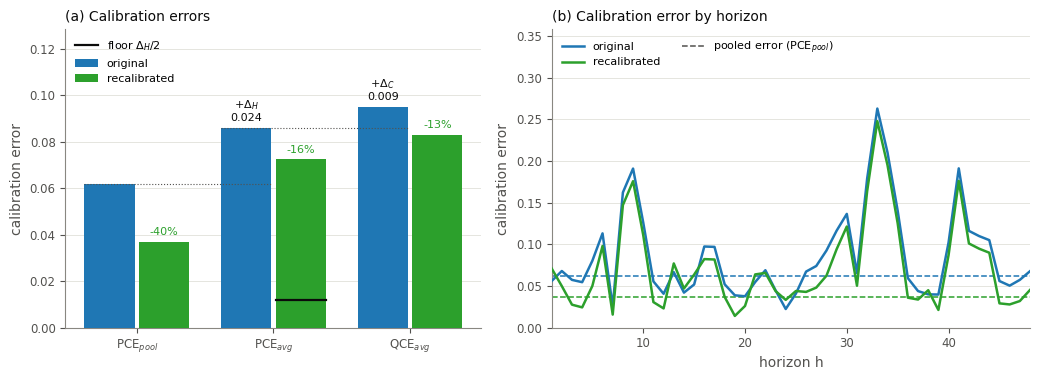

In [9]:
fig = plot_diagnostics(f, ev)

## 7. Bring your own model

A model only needs `predict_quantiles(contexts, prediction_length, levels) -> (B, H, Q)`. Any function can be wrapped with `FunctionForecaster`. Below is a Gaussian random-walk forecaster in a few lines, compared with the TSFM on the same windows.

In [10]:
from scipy.stats import norm


def gaussian_rw(contexts, prediction_length, levels):
    out = []
    for c in contexts:
        c = c[np.isfinite(c)]
        sigma = np.std(np.diff(c[-200:])) + 1e-8
        steps = np.sqrt(np.arange(1, prediction_length + 1))[:, None]
        out.append(c[-1] + sigma * steps * norm.ppf(levels)[None, :])
    return np.stack(out)

g = tc.forecast(tc.FunctionForecaster(gaussian_rw, name="gaussian-rw"), windows)
tc.compare({model.name: f, "gaussian-rw": g})[["pce_pool", "pce_avg", "qce_avg", "delta_h", "delta_c", "crps",
                                              "pce_avg_recal", "qce_avg_recal"]].round(4)

,pce_pool,pce_avg,qce_avg,delta_h,delta_c,crps,pce_avg_recal,qce_avg_recal
model,,,,,,,,
chronos-2,0.0554,0.0770,0.0863,0.0216,0.0093,65.0042,0.0724,0.0830
gaussian-rw,0.1215,0.2279,0.2409,0.1064,0.0130,275.3289,0.1516,0.1608


To make the model available by name, register it with `tc.register("gaussian-rw")(lambda: tc.FunctionForecaster(gaussian_rw, "gaussian-rw"))`.